# Conditional GAN 64×64 — AFHQ

Sebelum **Run All**:
1. **Add Input**: dataset **Animal Faces** (`andrewmvd`).
2. **Settings → Accelerator**: GPU.
3. **Settings → Internet**: On (untuk FID). Kalau Off, FID otomatis dilewati.

## Cell 1 — Setup dan konfigurasi

In [1]:
import json, os, random, shutil, subprocess, sys, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset
from torchvision.utils import make_grid, save_image

CFG = {
    "img_size": 64,
    "batch_size": 128,
    "z_dim": 100,
    "embed_dim": 50,
    "g_base": 64,
    "d_base": 64,
    "lr": 2e-4,
    "beta1": 0.5,
    "epochs": 100,
    "real_label": 0.9,
    "fid_every": 10,
    "fid_samples": 5000,
    "ckpt_every": 10,
    "use_fid": True,
    "resume": True,
    "seed": 42,
}

random.seed(CFG["seed"])
np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"])
torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK_DIR = Path("/kaggle/working")
OUT = WORK_DIR / "cgan_output"
(OUT / "samples").mkdir(parents=True, exist_ok=True)
(OUT / "config.json").write_text(json.dumps(CFG, indent=1))

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
SERIES = ["#2a78d6", "#eb6834"]

print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "(GPU tidak aktif!)")

Device: cuda Tesla T4


## Cell 2 — Load dataset ke RAM (64×64)

In [2]:
def find_dataset_root():
    for folder, subdirs, _ in os.walk("/kaggle/input"):
        if "train" in subdirs and "cat" in os.listdir(Path(folder) / "train"):
            return Path(folder)
    raise FileNotFoundError("Dataset belum ditambahkan. Klik Add Input, pilih Animal Faces dari andrewmvd.")


IMG = CFG["img_size"]
ROOT = find_dataset_root()
CLASSES = sorted(p.name for p in (ROOT / "train").iterdir() if p.is_dir())
N_CLASSES = len(CLASSES)

paths, label_list = [], []
for label, cls in enumerate(CLASSES):
    files = sorted(p for p in (ROOT / "train" / cls).iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    paths += files
    label_list += [label] * len(files)


def load_image(path):
    with Image.open(path) as im:
        im.draft("RGB", (IMG * 2, IMG * 2))  # decode JPEG langsung di ukuran kecil, jauh lebih cepat
        return np.asarray(im.convert("RGB").resize((IMG, IMG), Image.BICUBIC), dtype=np.uint8)


with ThreadPoolExecutor(max_workers=os.cpu_count() or 2) as pool:
    images = np.stack(list(pool.map(load_image, paths)))

# Disimpan sebagai uint8 (hemat RAM); diubah ke float [-1, 1] per batch di GPU.
images = torch.from_numpy(images).permute(0, 3, 1, 2).contiguous()
labels = torch.tensor(label_list, dtype=torch.long)

loader = DataLoader(TensorDataset(images, labels), batch_size=CFG["batch_size"], shuffle=True,
                    drop_last=True, pin_memory=DEVICE.type == "cuda")


def prepare_batch(imgs):
    x = imgs.to(DEVICE, non_blocking=True).float().div(127.5).sub(1)  # [0, 255] -> [-1, 1]
    flip = torch.rand(x.size(0), device=DEVICE) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)


print("Kelas:", dict(enumerate(CLASSES)))
print("Gambar:", tuple(images.shape), "| batch per epoch:", len(loader))

Kelas: {0: 'cat', 1: 'dog', 2: 'wild'}
Gambar: (14630, 3, 64, 64) | batch per epoch: 114


## Cell 3 — Cek data

Shape batch : (128, 3, 64, 64)
Rentang     : -1.0 sampai 1.0
Label batch : {'cat': 36, 'dog': 45, 'wild': 47}


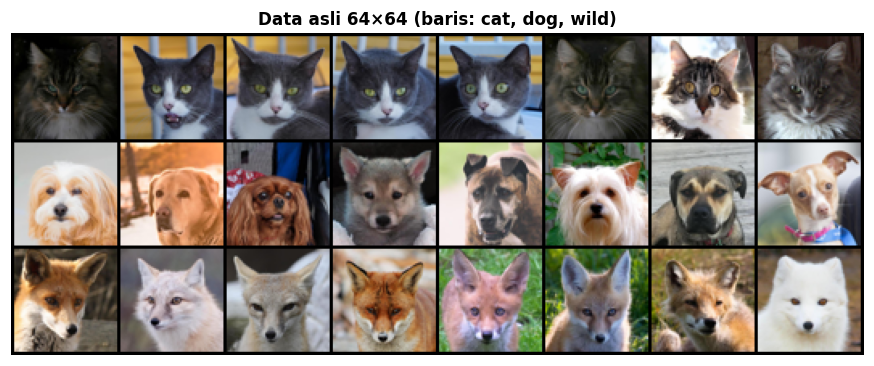

In [3]:
imgs, lbls = next(iter(loader))
x = prepare_batch(imgs)
print("Shape batch :", tuple(x.shape))
print("Rentang     :", round(x.min().item(), 3), "sampai", round(x.max().item(), 3))
print("Label batch :", {CLASSES[k]: int(v) for k, v in zip(*torch.unique(lbls, return_counts=True))})

per_class = torch.cat([images[labels == c][:8] for c in range(N_CLASSES)])
grid = make_grid(per_class, nrow=8, padding=2)
plt.figure(figsize=(10, 4))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Data asli 64×64 (baris: " + ", ".join(CLASSES) + ")")
plt.show()

## Cell 4 — Generator

In [4]:
class Generator(nn.Module):
    # noise + label -> gambar 64x64
    def __init__(self, z_dim, n_classes, embed_dim, base):
        super().__init__()
        self.label_embed = nn.Embedding(n_classes, embed_dim)

        def up(c_in, c_out):
            return [nn.ConvTranspose2d(c_in, c_out, 4, 2, 1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(True)]

        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim + embed_dim, base * 8, 4, 1, 0, bias=False),  # 1 -> 4
            nn.BatchNorm2d(base * 8), nn.ReLU(True),
            *up(base * 8, base * 4),  # 4 -> 8
            *up(base * 4, base * 2),  # 8 -> 16
            *up(base * 2, base),      # 16 -> 32
            nn.ConvTranspose2d(base, 3, 4, 2, 1),  # 32 -> 64
            nn.Tanh(),
        )

    def forward(self, z, y):
        h = torch.cat([z, self.label_embed(y)], dim=1)
        return self.net(h[:, :, None, None])

## Cell 5 — Discriminator

In [5]:
class Discriminator(nn.Module):
    # gambar + label -> skor asli/palsu (logit, tanpa sigmoid)
    def __init__(self, n_classes, img_size, base):
        super().__init__()
        self.img_size = img_size
        self.label_embed = nn.Embedding(n_classes, img_size * img_size)  # label jadi 1 channel 64x64

        def down(c_in, c_out, bn=True):
            layers = [nn.Conv2d(c_in, c_out, 4, 2, 1, bias=not bn)]
            if bn:
                layers.append(nn.BatchNorm2d(c_out))
            return layers + [nn.LeakyReLU(0.2, True)]

        self.net = nn.Sequential(
            *down(3 + 1, base, bn=False),  # 64 -> 32
            *down(base, base * 2),         # 32 -> 16
            *down(base * 2, base * 4),     # 16 -> 8
            *down(base * 4, base * 8),     # 8 -> 4
            nn.Conv2d(base * 8, 1, 4, 1, 0),  # 4 -> 1
        )

    def forward(self, x, y):
        label_map = self.label_embed(y).view(-1, 1, self.img_size, self.img_size)
        return self.net(torch.cat([x, label_map], dim=1)).view(-1)


def init_weights(m):
    # Inisialisasi standar DCGAN
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


G = Generator(CFG["z_dim"], N_CLASSES, CFG["embed_dim"], CFG["g_base"]).to(DEVICE)
D = Discriminator(N_CLASSES, IMG, CFG["d_base"]).to(DEVICE)
G.apply(init_weights)
D.apply(init_weights)

Discriminator(
  (label_embed): Embedding(3, 4096)
  (net): Sequential(
    (0): Conv2d(4, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1))
  )
)

## Cell 6 — Cek model

In [6]:
with torch.no_grad():
    z = torch.randn(4, CFG["z_dim"], device=DEVICE)
    y = torch.randint(0, N_CLASSES, (4,), device=DEVICE)
    fake = G(z, y)
    score = D(fake, y)

assert fake.shape == (4, 3, IMG, IMG), fake.shape
assert score.shape == (4,), score.shape
print("Output G:", tuple(fake.shape), "rentang", round(fake.min().item(), 3), "-", round(fake.max().item(), 3))
print("Output D:", tuple(score.shape))
print(f"Parameter G: {sum(p.numel() for p in G.parameters()):,}")
print(f"Parameter D: {sum(p.numel() for p in D.parameters()):,}")

Output G: (4, 3, 64, 64) rentang -0.776 - 0.801
Output D: (4,)
Parameter G: 3,986,457
Parameter D: 2,778,945


## Cell 7 — Loss dan optimizer

In [7]:
criterion = nn.BCEWithLogitsLoss()
opt_G = torch.optim.Adam(G.parameters(), lr=CFG["lr"], betas=(CFG["beta1"], 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=CFG["lr"], betas=(CFG["beta1"], 0.999))

## Cell 8 — Fungsi evaluasi (grid sampel dan FID)

In [8]:
# Noise tetap: 8 sampel per kelas, dipakai tiap epoch supaya perkembangan bisa dibandingkan.
fixed_gen = torch.Generator().manual_seed(CFG["seed"])
fixed_z = torch.randn(8 * N_CLASSES, CFG["z_dim"], generator=fixed_gen).to(DEVICE)
fixed_y = torch.arange(N_CLASSES).repeat_interleave(8).to(DEVICE)


@torch.no_grad()
def save_sample_grid(epoch):
    G.eval()
    fake = G(fixed_z, fixed_y)
    G.train()
    save_image(fake, OUT / "samples" / f"epoch_{epoch:03d}.png", nrow=8, normalize=True, value_range=(-1, 1))


fid_enabled = CFG["use_fid"]
fid = None
if fid_enabled:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch-fidelity", "torchmetrics"], check=True)
        from torchmetrics.image.fid import FrechetInceptionDistance

        fid = FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False).to(DEVICE)
        real_idx = torch.randperm(len(images))[:CFG["fid_samples"]]
        for i in range(0, len(real_idx), 250):
            fid.update(images[real_idx[i:i + 250]].to(DEVICE).float() / 255, real=True)
        print("FID aktif. Statistik gambar asli:", len(real_idx), "gambar")
    except Exception as e:
        fid_enabled = False
        print("FID dilewati (cek Settings → Internet):", type(e).__name__, e)


@torch.no_grad()
def compute_fid():
    G.eval()
    fid.reset()  # hanya menghapus statistik gambar palsu
    for i in range(0, CFG["fid_samples"], 250):
        b = min(250, CFG["fid_samples"] - i)
        y = torch.randint(0, N_CLASSES, (b,), device=DEVICE)
        fake = G(torch.randn(b, CFG["z_dim"], device=DEVICE), y)
        fid.update((fake + 1) / 2, real=False)
    G.train()
    return fid.compute().item()

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 484MB/s]


FID aktif. Statistik gambar asli: 5000 gambar


## Cell 9 — Training loop

In [9]:
ckpt_path = OUT / "checkpoint.pt"
history, start_epoch = [], 1

if CFG["resume"]:
    # Checkpoint dari sesi ini, atau dari output versi sebelumnya yang ditambahkan lewat Add Input.
    found = [ckpt_path] if ckpt_path.exists() else sorted(Path("/kaggle/input").glob("**/checkpoint.pt"))
    if found:
        ckpt = torch.load(found[0], map_location=DEVICE)
        G.load_state_dict(ckpt["G"]); D.load_state_dict(ckpt["D"])
        opt_G.load_state_dict(ckpt["opt_G"]); opt_D.load_state_dict(ckpt["opt_D"])
        history, start_epoch = ckpt["history"], ckpt["epoch"] + 1
        print("Lanjut dari", found[0], "epoch", ckpt["epoch"])

for epoch in range(start_epoch, CFG["epochs"] + 1):
    t0 = time.time()
    sums = defaultdict(float)

    for imgs, y in loader:
        real = prepare_batch(imgs)
        y = y.to(DEVICE, non_blocking=True)
        fake = G(torch.randn(real.size(0), CFG["z_dim"], device=DEVICE), y)

        # 1) Latih D: asli -> real_label (0.9), palsu -> 0
        opt_D.zero_grad(set_to_none=True)
        out_real = D(real, y)
        out_fake = D(fake.detach(), y)
        loss_D = (criterion(out_real, torch.full_like(out_real, CFG["real_label"]))
                  + criterion(out_fake, torch.zeros_like(out_fake)))
        loss_D.backward()
        opt_D.step()

        # 2) Latih G: buat D menilai gambar palsu sebagai asli
        opt_G.zero_grad(set_to_none=True)
        out_gen = D(fake, y)
        loss_G = criterion(out_gen, torch.ones_like(out_gen))
        loss_G.backward()
        opt_G.step()

        sums["loss_D"] += loss_D.item()
        sums["loss_G"] += loss_G.item()
        sums["D_x"] += torch.sigmoid(out_real).mean().item()
        sums["D_G_z"] += torch.sigmoid(out_fake).mean().item()

    record = {"epoch": epoch, **{k: v / len(loader) for k, v in sums.items()}, "detik": time.time() - t0}
    save_sample_grid(epoch)
    if fid_enabled and (epoch % CFG["fid_every"] == 0 or epoch == CFG["epochs"]):
        record["fid"] = compute_fid()
    history.append(record)
    pd.DataFrame(history).to_csv(OUT / "history.csv", index=False)

    print(f"Epoch {epoch:3d} | loss_D {record['loss_D']:.3f} | loss_G {record['loss_G']:.3f} | "
          f"D(x) {record['D_x']:.3f} | D(G(z)) {record['D_G_z']:.3f} | "
          + (f"FID {record['fid']:.2f} | " if "fid" in record else "") + f"{record['detik']:.0f} dtk")

    if epoch % CFG["ckpt_every"] == 0 or epoch == CFG["epochs"]:
        torch.save({"G": G.state_dict(), "D": D.state_dict(), "opt_G": opt_G.state_dict(),
                    "opt_D": opt_D.state_dict(), "history": history, "epoch": epoch, "cfg": CFG}, ckpt_path)

Epoch   1 | loss_D 1.124 | loss_G 6.668 | D(x) 0.719 | D(G(z)) 0.173 | 21 dtk
Epoch   2 | loss_D 0.718 | loss_G 5.596 | D(x) 0.781 | D(G(z)) 0.116 | 18 dtk
Epoch   3 | loss_D 0.774 | loss_G 4.799 | D(x) 0.744 | D(G(z)) 0.152 | 18 dtk
Epoch   4 | loss_D 0.783 | loss_G 4.760 | D(x) 0.742 | D(G(z)) 0.156 | 17 dtk
Epoch   5 | loss_D 0.825 | loss_G 4.880 | D(x) 0.728 | D(G(z)) 0.168 | 17 dtk
Epoch   6 | loss_D 0.838 | loss_G 4.900 | D(x) 0.725 | D(G(z)) 0.169 | 17 dtk
Epoch   7 | loss_D 0.823 | loss_G 4.397 | D(x) 0.725 | D(G(z)) 0.175 | 17 dtk
Epoch   8 | loss_D 0.859 | loss_G 4.650 | D(x) 0.715 | D(G(z)) 0.181 | 17 dtk
Epoch   9 | loss_D 0.788 | loss_G 4.374 | D(x) 0.732 | D(G(z)) 0.170 | 17 dtk
Epoch  10 | loss_D 0.827 | loss_G 4.263 | D(x) 0.718 | D(G(z)) 0.179 | FID 256.90 | 17 dtk
Epoch  11 | loss_D 0.895 | loss_G 4.546 | D(x) 0.701 | D(G(z)) 0.195 | 17 dtk
Epoch  12 | loss_D 0.839 | loss_G 4.469 | D(x) 0.714 | D(G(z)) 0.186 | 17 dtk
Epoch  13 | loss_D 0.879 | loss_G 4.459 | D(x) 0.69

## Cell 10 — Grafik metrik

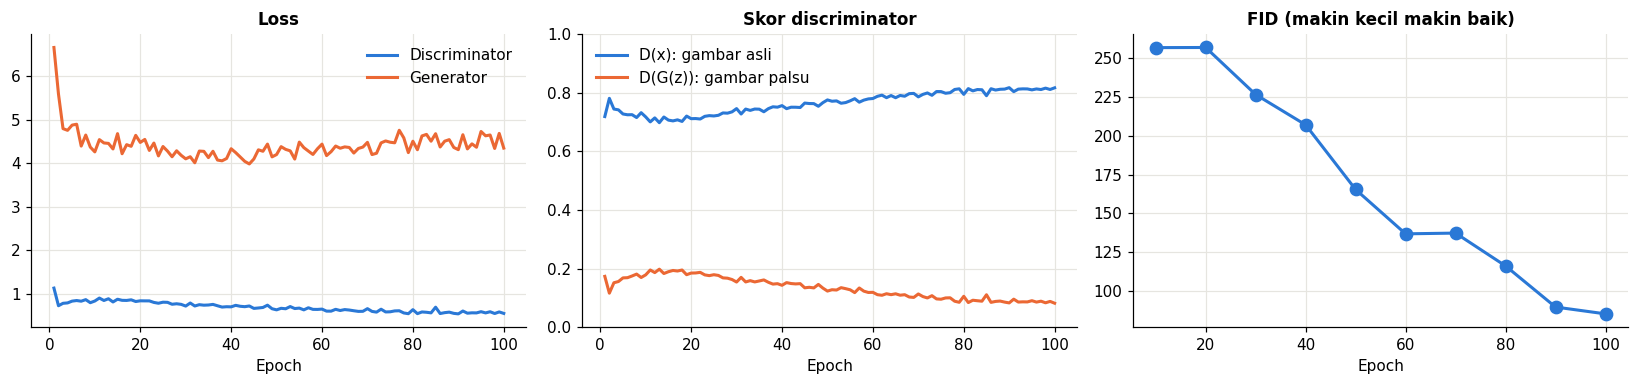

In [10]:
hist = pd.DataFrame(history)
has_fid = "fid" in hist and hist["fid"].notna().any()
fig, axes = plt.subplots(1, 3 if has_fid else 2, figsize=(15 if has_fid else 10, 3.6))

axes[0].plot(hist.epoch, hist.loss_D, color=SERIES[0], linewidth=2, label="Discriminator")
axes[0].plot(hist.epoch, hist.loss_G, color=SERIES[1], linewidth=2, label="Generator")
axes[0].set_title("Loss")

axes[1].plot(hist.epoch, hist.D_x, color=SERIES[0], linewidth=2, label="D(x): gambar asli")
axes[1].plot(hist.epoch, hist.D_G_z, color=SERIES[1], linewidth=2, label="D(G(z)): gambar palsu")
axes[1].set_title("Skor discriminator")
axes[1].set_ylim(0, 1)

if has_fid:
    f = hist.dropna(subset=["fid"])
    axes[2].plot(f.epoch, f.fid, color=SERIES[0], linewidth=2, marker="o", markersize=8)
    axes[2].set_title("FID (makin kecil makin baik)")

for ax in axes:
    ax.set_xlabel("Epoch")
for ax in axes[:2]:
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "metrik.png")
plt.show()

## Cell 11 — Hasil akhir

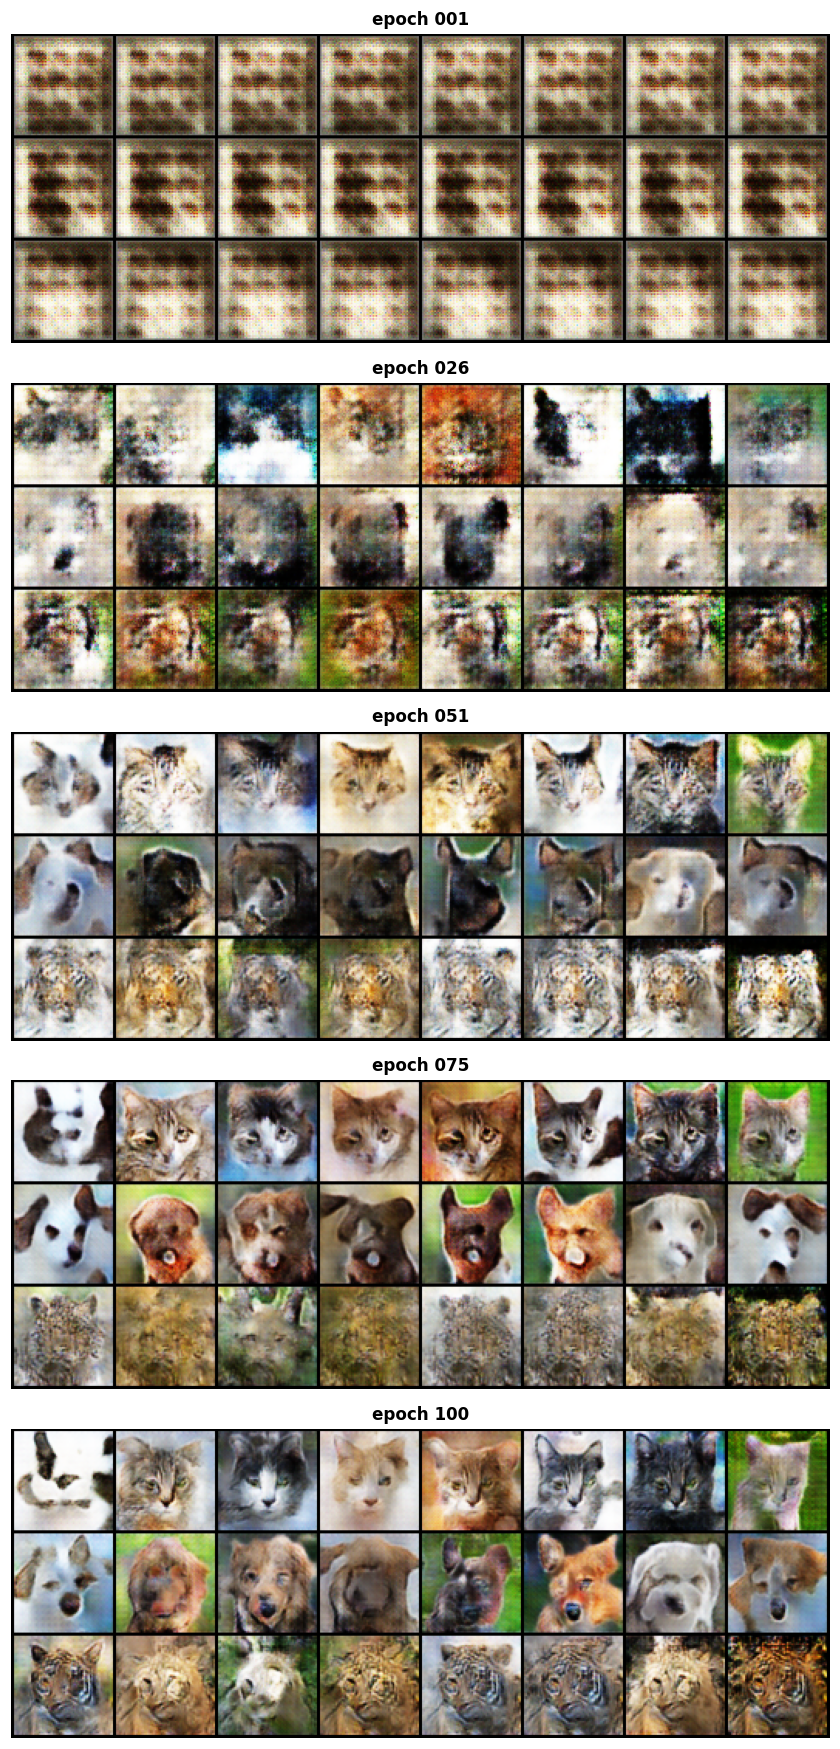

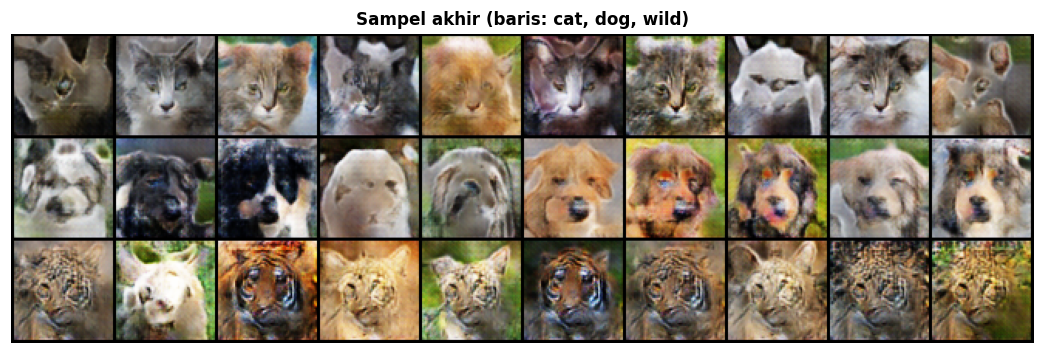

,kelas,keragaman_asli,keragaman_palsu,rasio
0,cat,0.3612,0.3149,0.872
1,dog,0.3494,0.3189,0.912
2,wild,0.3005,0.2586,0.861


Semua hasil tersimpan di cgan_output.zip


In [11]:
# 1) Perkembangan dari epoch awal sampai akhir (noise tetap)
sample_files = sorted((OUT / "samples").glob("epoch_*.png"))
picks = sorted({sample_files[i] for i in np.linspace(0, len(sample_files) - 1, 5).round().astype(int)})
fig, axes = plt.subplots(len(picks), 1, figsize=(8, 3.2 * len(picks)), squeeze=False)
for ax, path in zip(axes[:, 0], picks):
    ax.imshow(Image.open(path))
    ax.set_title(path.stem.replace("_", " "))
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "perkembangan.png")
plt.show()

# 2) Sampel akhir per kelas dengan noise baru
G.eval()
with torch.no_grad():
    y = torch.arange(N_CLASSES, device=DEVICE).repeat_interleave(10)
    final = G(torch.randn(len(y), CFG["z_dim"], device=DEVICE), y)
save_image(final, OUT / "sampel_akhir.png", nrow=10, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(12, 4))
plt.imshow(make_grid(final.cpu(), nrow=10, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
plt.axis("off")
plt.title("Sampel akhir (baris: " + ", ".join(CLASSES) + ")")
plt.show()

# 3) Cek mode collapse: keragaman gambar palsu dibanding gambar asli per kelas.
#    Rasio jauh di bawah 1 berarti gambar palsu terlalu mirip satu sama lain.
def mean_pair_rmse(x):
    x = x.flatten(1)
    a, b = torch.randint(0, len(x), (2000,)), torch.randint(0, len(x), (2000,))
    keep = a != b
    return ((x[a[keep]] - x[b[keep]]) ** 2).mean(dim=1).sqrt().mean().item()


rows = []
with torch.no_grad():
    for c, cls in enumerate(CLASSES):
        real = images[labels == c][:500].float() / 255
        fake = (G(torch.randn(500, CFG["z_dim"], device=DEVICE), torch.full((500,), c, device=DEVICE)).cpu() + 1) / 2
        r, f = mean_pair_rmse(real), mean_pair_rmse(fake)
        rows.append({"kelas": cls, "keragaman_asli": round(r, 4), "keragaman_palsu": round(f, 4), "rasio": round(f / r, 3)})
G.train()
diversity = pd.DataFrame(rows)
diversity.to_csv(OUT / "keragaman.csv", index=False)
display(diversity)

shutil.make_archive(str(WORK_DIR / "cgan_output"), "zip", OUT)
print("Semua hasil tersimpan di cgan_output.zip")